# Q-learning

Dans cette démonstration, nous étudions une implémentation complète du [Q-learning](https://fr.wikipedia.org/wiki/Q-learning) (Q-apprentissage), une méthode orientée valeur. Elle estime, pour chaque couple état / action, la valeur $Q(s, a)$ : le retour attendu (la somme des récompenses actualisées) quand on joue l'action $a$ dans l'état $s$, puis au mieux ensuite.

Ces valeurs, rangées dans une table (la Q-table), s'apprennent par [différence temporelle](https://fr.wikipedia.org/wiki/Temporal_difference_learning) : le Q-learning en est une méthode, qui apprend $Q(s, a)$ plutôt que la valeur $V(s)$ d'un état, et qui apprend la politique gloutonne tout en jouant une politique ε-gloutonne (contrôle hors politique).

Trois parties :

1. le labyrinthe des diapositives ;
2. FrozenLake, un environnement standard de [Gymnasium](https://gymnasium.farama.org/) (ex-OpenAI Gym) ;
3. le deep Q-learning (DQN) sur CartPole, à montrer après le chapitre « Renforcement profond ».

## Imports

In [1]:
import random
import time
from collections import deque

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np

## Q-learning tabulaire

La classe `AgentQLearning` tient la Q-table (un dictionnaire `(état, action) → valeur`, initialisé à 0) et trois méthodes :

- `met_a_jour_bellman` : la règle de la diapositive « Apprentissage des valeurs de la Q-table », $Q(s_t, a_t) \leftarrow Q(s_t, a_t) + \alpha \left[r_t + \gamma \max_a Q(s_{t+1}, a) - Q(s_t, a_t)\right]$ ;
- `episode` : un épisode joué ε-glouton (diapositive « Exploration et exploitation »), avec une mise à jour à chaque pas ;
- `apprend` : la suite des épisodes, $\varepsilon$ décroissant de 1 (tout au hasard) à 0 (toujours la meilleure action connue).

L'environnement suit l'interface de Gymnasium : `reset()` rend l'état de départ, `step(action)` rend le nouvel état, la récompense, et deux fins d'épisode possibles :

- `terminated` : l'état atteint est terminal (arrivée, chute) ; plus aucune récompense ne suit, la cible TD se réduit à $r_t$ ;
- `truncated` : l'épisode est coupé par une limite de pas ; l'état n'a rien de terminal, la cible garde son terme $\gamma \max_a Q(s_{t+1}, a)$.

In [2]:
class AgentQLearning:
  """Q-learning tabulaire : une Q-table, des épisodes ε-gloutons."""

  def __init__(self, actions, etats, environnement, gamma, alpha, nb_episodes):
    self.actions = actions
    self.environnement = environnement
    self.gamma = gamma  # facteur de réduction
    self.alpha = alpha  # pas d'apprentissage
    self.nb_episodes = nb_episodes
    self.rng = random.Random(0)  # graine fixée : résultats reproductibles
    self.table_q = {(s, a): 0.0 for s in etats for a in actions}

  def meilleure_action(self, s):
    return max(self.actions, key=lambda a: self.table_q[s, a])

  def met_a_jour_bellman(self, s, a, r, s_suivant, terminated: bool) -> None:
    if terminated:
      # État terminal : aucune récompense ne suit, la cible est r.
      cible = r
    else:
      cible = r + self.gamma * self.table_q[s_suivant, self.meilleure_action(s_suivant)]
    self.table_q[s, a] += self.alpha * (cible - self.table_q[s, a])

  def episode(self, epsilon: float) -> float:
    s, _ = self.environnement.reset()
    retour_total = 0.0
    fini = False
    while not fini:
      if self.rng.random() < epsilon:
        a = self.rng.choice(self.actions)  # exploration
      else:
        a = self.meilleure_action(s)  # exploitation
      s_suivant, r, terminated, truncated, _ = self.environnement.step(a)
      self.met_a_jour_bellman(s, a, r, s_suivant, terminated)
      retour_total += r
      s = s_suivant
      fini = terminated or truncated
    return retour_total

  def apprend(self, periode_affichage: int) -> list[float]:
    retours = []
    for i, epsilon in enumerate(np.linspace(1, 0, self.nb_episodes), start=1):
      retours.append(self.episode(epsilon))
      if i % periode_affichage == 0:
        moyenne = np.mean(retours[-periode_affichage:])
        print(f"épisode {i:5} : ε = {epsilon:.2f}, retour moyen = {moyenne:.2f}")
    return retours

## Le labyrinthe des diapositives

C'est le labyrinthe de la diapositive « Exemple — Problème », avec ses coordonnées (ligne, colonne), de (1, 1) en haut à gauche à (5, 5) : l'agent part de (3, 1), sort à droite de (3, 5), et chaque mouvement coûte 1 (récompense de −1). Un mouvement contre un mur laisse l'agent sur place, et coûte quand même 1.

In [3]:
# Le labyrinthe des diapositives : « # » pour un mur, « . » pour une case libre.
PLAN_LABYRINTHE = [
  ".#...",
  ".#.##",
  ".....",
  ".####",
  ".####",
]


class Labyrinthe:
  """Cases (ligne, colonne) de (1, 1) à (5, 5), comme dans les diapositives."""

  depart = (3, 1)  # la case de départ
  sortie = (3, 6)  # la sortie, à droite de (3, 5)
  mouvements = {"↑": (-1, 0), "→": (0, 1), "↓": (1, 0), "←": (0, -1)}

  def __init__(self) -> None:
    self.cases = [
      (ligne, colonne)
      for ligne in range(1, 6)
      for colonne in range(1, 6)
      if PLAN_LABYRINTHE[ligne - 1][colonne - 1] == "."
    ]

  def reset(self):
    self.etat = self.depart
    return self.etat, {}

  def step(self, action: str):
    d_ligne, d_colonne = self.mouvements[action]
    suivant = (self.etat[0] + d_ligne, self.etat[1] + d_colonne)
    if suivant == self.sortie:
      self.etat = suivant
      return suivant, -1.0, True, False, {}
    if suivant in self.cases:
      self.etat = suivant
    # Contre un mur ou un bord, l'agent reste sur place.
    return self.etat, -1.0, False, False, {}

  def affiche(self, texte_de) -> None:
    """Affiche le labyrinthe, avec texte_de(case) dans chaque case libre."""
    for ligne in range(1, 6):
      cases = " ".join(
        f"{texte_de((ligne, colonne)) if (ligne, colonne) in self.cases else '███':^5}"
        for colonne in range(1, 6)
      )
      gauche = "Entrée →" if ligne == 3 else ""
      droite = "→ Sortie" if ligne == 3 else ""
      print(f"{gauche:>10} {cases} {droite}")


labyrinthe = Labyrinthe()
labyrinthe.affiche(lambda case: f"{case[0]},{case[1]}")

            1,1   ███   1,3   1,4   1,5  
            2,1   ███   2,3   ███   ███  
  Entrée →  3,1   3,2   3,3   3,4   3,5  → Sortie
            4,1   ███   ███   ███   ███  
            5,1   ███   ███   ███   ███  


Apprentissage sur 1 000 épisodes, avec $\alpha = 0{,}1$ comme dans la diapositive « Exemple de mise à jour de la Q-table », et $\gamma = 1$ (pas de réduction) : $\max_a Q(s, a)$ doit alors tendre vers le retour du plus court chemin, c'est-à-dire l'opposé du nombre de pas qui restent jusqu'à la sortie. Les premiers épisodes, joués au hasard, durent des centaines de pas.

In [4]:
agent_laby = AgentQLearning(
  actions=list(Labyrinthe.mouvements),
  etats=labyrinthe.cases,
  environnement=labyrinthe,
  gamma=1.0,
  alpha=0.1,
  nb_episodes=1000,
)
retours_laby = agent_laby.apprend(periode_affichage=100)

épisode   100 : ε = 0.90, retour moyen = -96.89
épisode   200 : ε = 0.80, retour moyen = -43.65
épisode   300 : ε = 0.70, retour moyen = -25.91
épisode   400 : ε = 0.60, retour moyen = -16.58
épisode   500 : ε = 0.50, retour moyen = -12.59
épisode   600 : ε = 0.40, retour moyen = -10.40
épisode   700 : ε = 0.30, retour moyen = -7.85
épisode   800 : ε = 0.20, retour moyen = -7.16
épisode   900 : ε = 0.10, retour moyen = -6.03
épisode  1000 : ε = 0.00, retour moyen = -5.32


In [5]:
print("Retour du dernier épisode (ε = 0) :", retours_laby[-1])
print("\nmax_a Q(s, a) par case :")
labyrinthe.affiche(
  lambda case: f"{max(agent_laby.table_q[case, a] for a in Labyrinthe.mouvements):.1f}"
)
print("\nPolitique gloutonne :")
labyrinthe.affiche(agent_laby.meilleure_action)

Retour du dernier épisode (ε = 0) : -5.0

max_a Q(s, a) par case :
           -7.0   ███  -5.0  -6.0  -7.0  
           -6.0   ███  -4.0   ███   ███  
  Entrée → -5.0  -4.0  -3.0  -2.0  -1.0  → Sortie
           -6.0   ███   ███   ███   ███  
           -7.0   ███   ███   ███   ███  

Politique gloutonne :
             ↓    ███    ↓     ←     ←   
             ↓    ███    ↓    ███   ███  
  Entrée →   →     →     →     →     →   → Sortie
             ↑    ███   ███   ███   ███  
             ↑    ███   ███   ███   ███  


Le dernier épisode, joué sans exploration, a un retour de −5 : le plus court chemin de (3, 1) à la sortie fait 5 pas. Les valeurs $\max_a Q(s, a)$ sont celles de la diapositive « Exemple — Solution orientée valeur », et la politique gloutonne, celle qu'elle en tire.

## FrozenLake

[FrozenLake](https://gymnasium.farama.org/environments/toy_text/frozen_lake/) : traverser un lac gelé, une grille 4 × 4, du départ `S` à l'arrivée `G` sans tomber dans un trou `H` (`F` : de la glace).

- États : les 16 cases, numérotées `4 × ligne + colonne` (de 0 à 15) ; actions : 0 ←, 1 ↓, 2 →, 3 ↑.
- Récompense : 1 à l'arrivée, 0 partout ailleurs ; l'arrivée et les trous terminent l'épisode (`terminated`).
- Lac glissant (le réglage par défaut) : l'agent ne va dans la direction voulue qu'une fois sur trois, et glisse sinon vers l'un des deux côtés.
- 100 pas au plus : au-delà, l'épisode est coupé (`truncated`).

In [6]:
lac_gele = gym.make("FrozenLake-v1")
lac_gele.reset(seed=0)  # graine fixée : glissades reproductibles
for ligne in lac_gele.unwrapped.desc.astype(str):
  print(" ".join(ligne))

S F F F
F H F H
F F F H
H F F G


Apprentissage sur 10 000 épisodes, avec $\gamma = 0{,}99$ : la seule récompense arrive au bout du chemin. Avec $\gamma = 0{,}9$, elle compte de moins en moins à mesure qu'elle s'éloigne, et l'agent préfère arriver vite, quitte à frôler les trous.

In [7]:
agent_lac_gele = AgentQLearning(
  actions=[0, 1, 2, 3],
  etats=list(range(16)),
  environnement=lac_gele,
  gamma=0.99,
  alpha=0.1,
  nb_episodes=10_000,
)
retours_lac_gele = agent_lac_gele.apprend(periode_affichage=1000)

épisode  1000 : ε = 0.90, retour moyen = 0.02
épisode  2000 : ε = 0.80, retour moyen = 0.03
épisode  3000 : ε = 0.70, retour moyen = 0.03
épisode  4000 : ε = 0.60, retour moyen = 0.05
épisode  5000 : ε = 0.50, retour moyen = 0.05
épisode  6000 : ε = 0.40, retour moyen = 0.09
épisode  7000 : ε = 0.30, retour moyen = 0.12
épisode  8000 : ε = 0.20, retour moyen = 0.20
épisode  9000 : ε = 0.10, retour moyen = 0.32
épisode 10000 : ε = 0.00, retour moyen = 0.54


Le retour d'un épisode vaut 0 ou 1 : sa moyenne glissante est le taux de réussite. Il monte à mesure que $\varepsilon$ baisse : l'agent explore de moins en moins et joue de plus en plus ce qu'il a appris.

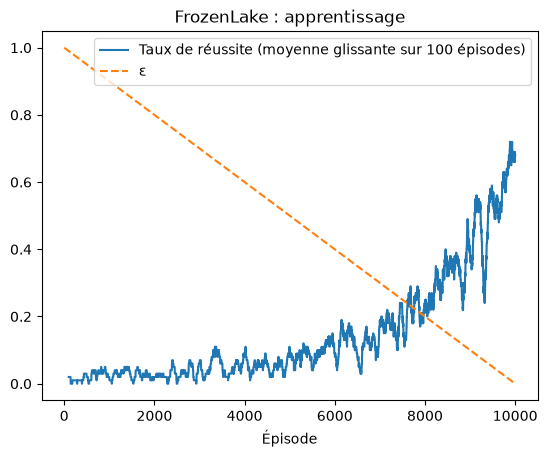

In [8]:
fenetre = 100
moyenne_glissante = np.convolve(
  retours_lac_gele, np.ones(fenetre) / fenetre, mode="valid"
)
episodes = np.arange(1, len(retours_lac_gele) + 1)
plt.plot(
  episodes[fenetre - 1 :],
  moyenne_glissante,
  label="Taux de réussite (moyenne glissante sur 100 épisodes)",
)
plt.plot(episodes, np.linspace(1, 0, len(episodes)), "--", label="ε")
plt.xlabel("Épisode")
plt.title("FrozenLake : apprentissage")
plt.legend()
plt.show()

La politique gloutonne apprise, jouée sur 1 000 épisodes, comparée à une politique qui joue au hasard, puis dessinée en flèches sur la grille :

In [9]:
def calcule_taux_reussite(politique, nb_episodes: int = 1000) -> float:
  """Part des épisodes qui atteignent l'arrivée en jouant politique(état)."""
  reussites = 0.0
  for _ in range(nb_episodes):
    s, _ = lac_gele.reset()
    fini = False
    while not fini:
      s, r, terminated, truncated, _ = lac_gele.step(politique(s))
      fini = terminated or truncated
    reussites += r
  return reussites / nb_episodes


rng = random.Random(0)
print(
  f"Politique gloutonne apprise : {calcule_taux_reussite(agent_lac_gele.meilleure_action):.1%}"
)
print(
  f"Politique aléatoire : {calcule_taux_reussite(lambda s: rng.choice([0, 1, 2, 3])):.1%}"
)

fleches = "←↓→↑"  # actions 0, 1, 2, 3
description = lac_gele.unwrapped.desc.astype(str)
for ligne in range(4):
  print(
    " ".join(
      description[ligne, colonne]
      if description[ligne, colonne] in "HG"
      else fleches[agent_lac_gele.meilleure_action(4 * ligne + colonne)]
      for colonne in range(4)
    )
  )

Politique gloutonne apprise : 75.2%
Politique aléatoire : 1.6%
← ↑ ↑ ↑
← H → H
↑ ↓ ← H
H → ↓ G


Environ trois réussites sur quatre : c'est à peu près le mieux possible sur ce lac glissant (74 % en 100 pas, d'après la politique optimale calculée sur le modèle de l'environnement). Les flèches qui semblent absurdes (← au départ, ↑ sur la première ligne) poussent contre un bord : l'agent ne peut alors glisser que dans des directions sans trou.

## Deep Q-learning sur CartPole

À montrer après le chapitre « Renforcement profond » : cette partie reprend les diapositives « Deep Q-learning : principe », « Mémoire de rejeu » et « Réseau cible ».

[CartPole](https://gymnasium.farama.org/environments/classic_control/cart_pole/) : tenir un mât en équilibre sur un chariot.

- État : 4 nombres réels (position et vitesse du chariot, angle et vitesse angulaire du mât) ; une Q-table ne peut pas avoir une ligne par état (diapositive « Limitations ») : un réseau de neurones prédit $Q(s, a)$.
- Actions : pousser le chariot à gauche (0) ou à droite (1).
- Récompense : +1 à chaque pas où le mât tient ; l'épisode se termine (`terminated`) quand le mât penche de plus de 12° ou que le chariot sort de la piste, et il est coupé (`truncated`) à 500 pas : le retour vaut au plus 500.

La graine est fixée, et l'entraînement tient en quelques minutes sur CPU (pas besoin de GPU). Comme référence, le retour moyen d'une politique qui joue au hasard :

In [10]:
import torch
from torch import nn

GRAINE = 0
random.seed(GRAINE)
torch.manual_seed(GRAINE)

cartpole = gym.make("CartPole-v1")

# Référence : une politique qui joue au hasard, sur 100 épisodes.
retours_aleatoires = []
for i in range(100):
  cartpole.reset(seed=GRAINE + i)
  retour_episode, fini = 0.0, False
  while not fini:
    _, recompense, terminated, truncated, _ = cartpole.step(random.randrange(2))
    retour_episode += recompense
    fini = terminated or truncated
  retours_aleatoires.append(retour_episode)
print(f"Politique aléatoire, retour moyen : {np.mean(retours_aleatoires):.1f}")

Politique aléatoire, retour moyen : 20.8


### Le réseau et le réseau cible

Le réseau prend l'état (4 nombres) et rend une valeur $Q(s, a)$ par action (2 sorties). Le réseau cible $\hat{Q}$ en est une copie figée, qui calcule la cible et n'est remise à jour que tous les $C$ pas (diapositive « Réseau cible »).

In [11]:
def fabrique_reseau_q() -> nn.Module:
  """Q(s, ·) : 4 nombres en entrée, une valeur par action en sortie."""
  return nn.Sequential(
    nn.Linear(4, 128),
    nn.ReLU(),
    nn.Linear(128, 128),
    nn.ReLU(),
    nn.Linear(128, 2),
  )


reseau_q = fabrique_reseau_q()
reseau_cible = fabrique_reseau_q()  # le réseau cible
reseau_cible.load_state_dict(reseau_q.state_dict())  # une copie figée du réseau
optimiseur = torch.optim.Adam(reseau_q.parameters(), lr=1e-3)

### La mémoire de rejeu

Elle garde les dernières transitions jouées (état, action, récompense, état suivant, et si cet état est terminal), et l'apprentissage tire ses lots au hasard dedans : des exemples moins corrélés que des pas successifs, et chaque transition qui sert plusieurs fois (diapositive « Mémoire de rejeu »).

In [12]:
class MemoireRejeu:
  """Les dernières transitions jouées, pour en tirer des lots au hasard."""

  def __init__(self, capacite: int) -> None:
    self.transitions = deque(maxlen=capacite)  # pleine, elle oublie les plus anciennes

  def ajoute(self, etat, action, recompense, etat_suivant, terminated) -> None:
    self.transitions.append((etat, action, recompense, etat_suivant, terminated))

  def echantillonne(self, taille_lot: int):
    lot = random.sample(self.transitions, taille_lot)
    etats, actions, recompenses, etats_suivants, terminated = zip(*lot)
    return (
      torch.tensor(np.array(etats)),
      torch.tensor(actions),
      torch.tensor(recompenses, dtype=torch.float32),
      torch.tensor(np.array(etats_suivants)),
      torch.tensor(terminated, dtype=torch.float32),
    )

  def __len__(self) -> int:
    return len(self.transitions)


memoire = MemoireRejeu(capacite=50_000)

### L'apprentissage

Chaque pas de jeu, ε-glouton, ajoute sa transition à la mémoire, puis fait une descente de gradient sur un lot de 128 transitions tirées au hasard, avec la perte de la diapositive « Réseau cible » : $L = \left(r + \gamma \max_{a'} \hat{Q}(s', a') - Q(s, a)\right)^2$, ou $(r - Q(s, a))^2$ quand $s'$ est terminal (mais pas quand l'épisode est seulement coupé à 500 pas). $\varepsilon$ décroît de 1 à 0,05 sur les 5 000 premiers pas, et le réseau cible est recopié tous les $C = 200$ pas.

In [13]:
GAMMA = 0.99
TAILLE_LOT = 128


def choisit_action(etat, epsilon: float) -> int:
  if random.random() < epsilon:
    return random.randrange(2)  # exploration
  with torch.no_grad():
    return int(reseau_q(torch.tensor(etat)).argmax())  # exploitation


def fait_pas_entrainement() -> None:
  """Une descente de gradient sur un lot tiré de la mémoire de rejeu."""
  etats, actions, recompenses, etats_suivants, terminated = memoire.echantillonne(
    TAILLE_LOT
  )
  # Q(s, a) des actions jouées.
  q = reseau_q(etats).gather(1, actions.unsqueeze(1)).squeeze(1)
  with torch.no_grad():
    # Cible r + γ max_a' Q̂(s', a'), calculée par le réseau cible ;
    # r seul quand s' est terminal.
    q_suivant = reseau_cible(etats_suivants).max(dim=1).values
    cible = recompenses + GAMMA * q_suivant * (1 - terminated)
  perte = nn.functional.mse_loss(q, cible)  # erreur TD au carré
  optimiseur.zero_grad()
  perte.backward()
  optimiseur.step()

In [14]:
NB_EPISODES = 300
C = 200  # pas entre deux copies vers le réseau cible
PAS_EPSILON = 5_000  # pas sur lesquels ε décroît de 1 jusqu'à 0,05

retours = []
pas = 0
debut = time.perf_counter()
for episode in range(1, NB_EPISODES + 1):
  etat, _ = cartpole.reset(seed=GRAINE + 100 + episode)
  retour_episode, fini = 0.0, False
  while not fini:
    epsilon = max(0.05, 1 - pas / PAS_EPSILON)
    action = choisit_action(etat, epsilon)
    etat_suivant, recompense, terminated, truncated, _ = cartpole.step(action)
    memoire.ajoute(etat, action, recompense, etat_suivant, terminated)
    etat = etat_suivant
    retour_episode += recompense
    fini = terminated or truncated
    pas += 1
    if len(memoire) >= 1000:  # attendre d'avoir assez de transitions
      fait_pas_entrainement()
    if pas % C == 0:
      reseau_cible.load_state_dict(reseau_q.state_dict())
  retours.append(retour_episode)
  if episode % 50 == 0:
    moyenne = np.mean(retours[-50:])
    print(
      f"épisode {episode:3} : {pas:6} pas, ε = {epsilon:.2f}, retour moyen des 50 derniers = {moyenne:5.1f}"
    )
print(f"Durée de l'entraînement : {(time.perf_counter() - debut) / 60:.1f} min")

épisode  50 :   1271 pas, ε = 0.75, retour moyen des 50 derniers =  25.4
épisode 100 :   6838 pas, ε = 0.05, retour moyen des 50 derniers = 111.3
épisode 150 :  13941 pas, ε = 0.05, retour moyen des 50 derniers = 142.1
épisode 200 :  20881 pas, ε = 0.05, retour moyen des 50 derniers = 138.8
épisode 250 :  33418 pas, ε = 0.05, retour moyen des 50 derniers = 250.7
épisode 300 :  51784 pas, ε = 0.05, retour moyen des 50 derniers = 367.3
Durée de l'entraînement : 5.2 min


### La courbe des retours

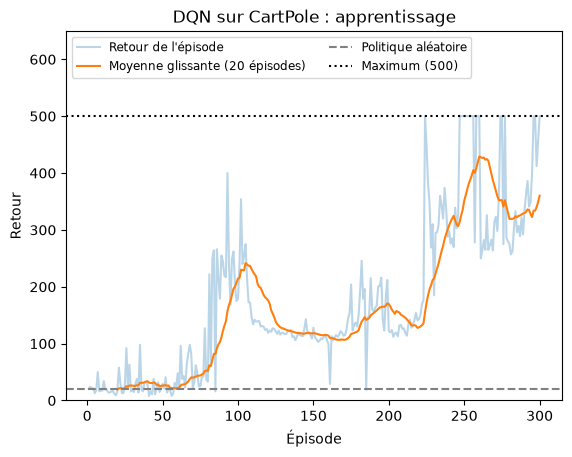

In [15]:
fenetre = 20
moyenne_glissante = np.convolve(retours, np.ones(fenetre) / fenetre, mode="valid")
episodes = np.arange(1, len(retours) + 1)
plt.plot(episodes, retours, alpha=0.3, label="Retour de l'épisode")
plt.plot(
  episodes[fenetre - 1 :], moyenne_glissante, label="Moyenne glissante (20 épisodes)"
)
plt.axhline(
  np.mean(retours_aleatoires), color="gray", linestyle="--", label="Politique aléatoire"
)
plt.axhline(500, color="black", linestyle=":", label="Maximum (500)")
plt.xlabel("Épisode")
plt.ylabel("Retour")
plt.title("DQN sur CartPole : apprentissage")
plt.ylim(0, 650)
plt.legend(loc="upper left", ncol=2, fontsize="small")
plt.show()

### Évaluation

La politique gloutonne ($\varepsilon = 0$) du réseau appris, sur 20 nouveaux épisodes :

In [16]:
retours_gloutons = []
for i in range(20):
  etat, _ = cartpole.reset(seed=10_000 + i)
  retour_episode, fini = 0.0, False
  while not fini:
    etat, recompense, terminated, truncated, _ = cartpole.step(
      choisit_action(etat, 0.0)
    )
    retour_episode += recompense
    fini = terminated or truncated
  retours_gloutons.append(retour_episode)
print(
  f"Politique gloutonne du DQN, retour moyen : {np.mean(retours_gloutons):.1f} (min {min(retours_gloutons):.0f}, max {max(retours_gloutons):.0f})"
)
print(f"Politique aléatoire, retour moyen : {np.mean(retours_aleatoires):.1f}")

Politique gloutonne du DQN, retour moyen : 440.9 (min 405, max 500)
Politique aléatoire, retour moyen : 20.8


Le DQN fait bien mieux que le hasard (un retour d'environ 20), et sa politique gloutonne approche souvent le maximum de 500. La courbe n'est pas monotone : l'apprentissage progresse par paliers, et peut aussi régresser pendant plusieurs dizaines d'épisodes, d'où les astuces de stabilité des diapositives et leurs successeurs. Malgré la graine, une autre machine ou une autre version de PyTorch peut donner une autre courbe, et un niveau final un peu différent. D'une graine à l'autre, l'entraînement est même instable : sur cinq graines essayées, quatre atteignent 500 et une plafonne vers 130, ce qui montre pourquoi le DQN a besoin de ses astuces de stabilité.

Pour aller plus loin, le Double DQN (diapositive « Double DQN ») ne change que le calcul de la cible dans `fait_pas_entrainement` : l'action suivante est choisie par le réseau en ligne, et évaluée par le réseau cible.

```python
actions_suivantes = reseau_q(etats_suivants).argmax(dim=1, keepdim=True)
q_suivant = reseau_cible(etats_suivants).gather(1, actions_suivantes).squeeze(1)
```